In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
pd.set_option('display.float_format', '{:.4f}'.format)

In [2]:
import seaborn as sns
sns.set()

### Import train+test

In [3]:
import os 

In [4]:
path = 'D:\Duy\Study\FA_course\Credit_risk\First_model'
os.chdir(path)

In [5]:
"""x_train = pd.read_csv('x_train.csv', index_col=0) 
y_train = pd.read_csv('y_train.csv',index_col=0) 
x_test = pd.read_csv('x_test.csv',index_col=0)
y_test = pd.read_csv('y_test.csv',index_col=0)"""

In [6]:
x_train.shape

(26059, 65)

In [7]:
y_train.shape

(26059, 1)

### Selecting features

In [8]:
x_train.columns.values

<ArrowStringArray>
[                       'person_age',                     'person_income',
             'person_home_ownership',                 'person_emp_length',
                       'loan_intent',                        'loan_grade',
                         'loan_amnt',                     'loan_int_rate',
               'loan_percent_income',         'cb_person_default_on_file',
        'cb_person_cred_hist_length',    'person_home_ownership:MORTGAGE',
       'person_home_ownership:OTHER',         'person_home_ownership:OWN',
        'person_home_ownership:RENT',     'loan_intent:DEBTCONSOLIDATION',
             'loan_intent:EDUCATION',       'loan_intent:HOMEIMPROVEMENT',
               'loan_intent:MEDICAL',              'loan_intent:PERSONAL',
               'loan_intent:VENTURE',                      'loan_grade:A',
                      'loan_grade:B',                      'loan_grade:C',
                      'loan_grade:D',                      'loan_grade:E',
      

In [9]:
x_train_with_ref_cat = x_train.loc[:, ['person_home_ownership:MORTGAGE',
 'person_home_ownership:OWN',
 'person_home_ownership:RENT_OTHER',
 'loan_intent:DEBTCONSOLIDATION',
 'loan_intent:EDUCATION',
 'loan_intent:HOMEIMPROVEMENT',
 'loan_intent:MEDICAL',
 'loan_intent:PERSONAL',
 'loan_intent:VENTURE',
 'loan_grade:A',
 'loan_grade:B',
 'loan_grade:C',
 'loan_grade:D',
 'loan_grade:E',
 'loan_grade:F',
 'loan_grade:G',
 'person_age:20-30',
 'person_age:31-50',
 'person_age:>50',
 'person_emp_length:<1',
 'person_emp_length:1-2',
 'person_emp_length:2-4',
 'person_emp_length:4-6',
 'person_emp_length:6-8',
 'person_emp_length:>=8',
 'loan_int_rate:<9.45',
 'loan_int_rate:9.45-12.68',              
 'loan_int_rate:>12.68',
 'cb_person_cred_hist_length:<=3',
 'cb_person_cred_hist_length:3-4',
 'cb_person_cred_hist_length:4-9',
 'cb_person_cred_hist_length:>9',
 'person_income:<25000',
 'person_income:25k-35k',
 'person_income:35k-45k',
 'person_income:45k-55k',
 'person_income:55k-63k',
 'person_income:63k-73k',
 'person_income:73k-80k',
 'person_income:80k-100k',
 'person_income:100k-130k',
 'person_income:>130000',
 'loan_percent_income:<0.07',
 'loan_percent_income:0.07-0.12',
 'loan_percent_income:0.12-0.15',
 'loan_percent_income:0.15-0.25',
 'loan_percent_income:>0.25'
]]

In [10]:
ref_categories = ['person_home_ownership:RENT_OTHER',
'loan_intent:DEBTCONSOLIDATION',
'loan_grade:G',
'person_age:20-30',
'person_emp_length:<1',
'loan_int_rate:<9.45',
'cb_person_cred_hist_length:<=3',
'person_income:<25000',
'loan_percent_income:<0.07'
]

In [11]:
x_train = x_train_with_ref_cat.drop(ref_categories, axis = 1)
x_train

,person_home_ownership:MORTGAGE,person_home_ownership:OWN,loan_intent:EDUCATION,loan_intent:HOMEIMPROVEMENT,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,...,person_income:55k-63k,person_income:63k-73k,person_income:73k-80k,person_income:80k-100k,person_income:100k-130k,person_income:>130000,loan_percent_income:0.07-0.12,loan_percent_income:0.12-0.15,loan_percent_income:0.15-0.25,loan_percent_income:>0.25
14169,1,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
27289,0,1,0,0,0,0,1,0,1,0,...,0,0,0,0,1,0,0,0,1,0
28389,0,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1338,0,0,0,1,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
7047,0,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29802,1,0,0,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,1,0
5390,1,0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
860,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
15795,0,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0


### Train model

In [12]:
from sklearn.linear_model import LogisticRegression

In [13]:
log_reg = LogisticRegression()

In [14]:
log_reg.fit(x_train, y_train)

C:\Users\admin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [15]:
# Metrics

print(f'Model intercept: {log_reg.intercept_}')
print(f'Model coefs+const: {log_reg.coef_}')


Model intercept: [-2.92551075]
Model coefs+const: [[ 0.82005245  2.46280774  0.86190826 -0.04527807  0.19354442  0.63824978
   1.07951307  3.37787722  3.33961776  3.00419464  0.84328697  0.57615371
   0.11765394 -0.05847032 -0.3437162   0.06540554  0.32207941  0.40910131
   0.24011879  0.25966535 -0.36356734 -0.38308846  0.01550627  0.09406134
   0.18428219  0.67366504  1.29731474  1.39133461  1.2839652   1.39257073
   1.66409097  2.08577821  1.99681634  1.72295781 -0.14229056  0.05545392
  -0.18184282 -2.04506306]]


### Compare with sm.OLS

In [16]:
import statsmodels.api as sm

In [17]:
x_train_with_const = sm.add_constant(x_train) 
x_test_with_const = sm.add_constant(x_test)

In [18]:
model_sm = sm.Logit(y_train, x_train_with_const)

In [19]:
result_sm = model_sm.fit()

Optimization terminated successfully.
         Current function value: 0.338813
         Iterations 8


In [20]:
result_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:            loan_status   No. Observations:                26059
Model:                          Logit   Df Residuals:                    26020
Method:                           MLE   Df Model:                           38
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3545
Time:                        15:58:28   Log-Likelihood:                -8829.1
converged:                       True   LL-Null:                       -13677.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==================================================================================================
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             -6.2626      1.048     -5.978      0.000      -8.316      -4.209
person_home_ownership:MORTGAGE     0.8201      0.045     18.280      0.000       0.732       0.908
person_home_ownership:OWN          2.5230      0.106     23.757      0.000       2.315       2.731
loan_intent:EDUCATION              0.8693      0.064     13.639      0.000       0.744       0.994
loan_intent:HOMEIMPROVEMENT       -0.0461      0.071     -0.651      0.515      -0.185       0.093
loan_intent:MEDICAL                0.1978      0.060      3.278      0.001       0.080       0.316
loan_intent:PERSONAL               0.6485      0.065      9.945      0.000       0.521       0.776
loan_intent:VENTURE                1.0968      0.069     15.943      0.000       0.962       1.232
loan_grade:A                       6.6786      1.042      6.406      0.000       4.635       8.722
loan_grade:B                       6.6057      1.031      6.410      0.000       4.586       8.626
loan_grade:C                       6.2215      1.027      6.059      0.000       4.209       8.234
loan_grade:D                       4.0371      1.026      3.933      0.000       2.025       6.049
loan_grade:E                       3.7704      1.029      3.664      0.000       1.753       5.787
loan_grade:F                       3.3782      1.042      3.241      0.001       1.335       5.421
person_age:31-50                  -0.0735      0.063     -1.165      0.244      -0.197       0.050
person_age:>50                    -0.4257      0.217     -1.958      0.050      -0.852       0.000
person_emp_length:1-2              0.0526      0.075      0.703      0.482      -0.094       0.199
person_emp_length:2-4              0.3158      0.060      5.228      0.000       0.197       0.434
person_emp_length:4-6              0.4024      0.065      6.159      0.000       0.274       0.530
person_emp_length:6-8              0.2318      0.071      3.288      0.001       0.094       0.370
person_emp_length:>=8              0.2494      0.067      3.722      0.000       0.118       0.381
loan_int_rate:9.45-12.68          -0.3341      0.161     -2.077      0.038      -0.649      -0.019
loan_int_rate:>12.68              -0.2982      0.185     -1.615      0.106      -0.660       0.064
cb_person_cred_hist_length:3-4     0.0135      0.055      0.247      0.805      -0.093       0.120
cb_person_cred_hist_length:4-9     0.0994      0.054      1.835      0.066      -0.007       0.205
cb_person_cred_hist_length:>9      0.2024      0.077      2.615      0.009       0.051       0.354
person_income:25k-35k              0.7301      0.071     10.354      0.000       0.592       0.868
person_income:35k-45k              1.3584      0.072     18.903      0.000       1.218       1.499
person_income:45k-55k              1.4548      0.075     19.311      0.000       1.307       1.602
person_income:55k-63k              1.3462      0.078     17.231      0.00

### Table metrics

In [21]:
feature_name = x_train.columns.values

In [22]:
summary_table = pd.DataFrame(columns=['Feature name'], data=feature_name)
summary_table['Coefs'] = np.transpose(log_reg.coef_)
summary_table.index = summary_table.index + 1
summary_table.loc[0] = ['Intercept', log_reg.intercept_[0]]
summary_table = summary_table.sort_index()

In [23]:
# p-value calculation (source: StackOverflow)

def logit_pvalue(model, x):
    """ Calculate z-scores for scikit-learn LogisticRegression.
    parameters:
        model: fitted sklearn.linear_model.LogisticRegression with intercept and large C
        x:     matrix on which the model was fit
    This function uses asymtptics for maximum likelihood estimates.
    """
    p = model.predict_proba(x)
    n = len(p)
    m = len(model.coef_[0]) + 1
    coefs = np.concatenate([model.intercept_, model.coef_[0]])
    x_full = np.matrix(np.insert(np.array(x), 0, 1, axis = 1))
    ans = np.zeros((m, m))
    for i in range(n):
        ans = ans + np.dot(np.transpose(x_full[i, :]), x_full[i, :]) * p[i,1] * p[i, 0]
    vcov = np.linalg.inv(np.matrix(ans))
    se = np.sqrt(np.diag(vcov))
    t =  coefs/se  
    p = (1 - stats.norm.cdf(abs(t))) * 2
    return p

In [24]:
p_values = logit_pvalue(log_reg, x_train)
summary_table['p-value'] = p_values
summary_table

,Feature name,Coefs,p-value
0,Intercept,-2.9255,0.0000
1,person_home_ownership:MORTGAGE,0.8201,0.0000
2,person_home_ownership:OWN,2.4628,0.0000
3,loan_intent:EDUCATION,0.8619,0.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0453,0.5207
5,loan_intent:MEDICAL,0.1935,0.0013
6,loan_intent:PERSONAL,0.6382,0.0000
7,loan_intent:VENTURE,1.0795,0.0000
8,loan_grade:A,3.3779,0.0000
9,loan_grade:B,3.3396,0.0000


In [25]:
#summary_table.to_csv('p-values.csv')

In [26]:
# train data with significant features
x_train = x_train.loc[: , ['person_home_ownership:MORTGAGE',
'person_home_ownership:OWN',
'loan_intent:EDUCATION',
'loan_intent:HOMEIMPROVEMENT',
'loan_intent:MEDICAL',
'loan_intent:PERSONAL',
'loan_intent:VENTURE',
'loan_grade:A',
'loan_grade:B',
'loan_grade:C',
'loan_grade:D',
'loan_grade:E',
'loan_grade:F',
'person_emp_length:1-2',
'person_emp_length:2-4',
'person_emp_length:4-6',
'person_emp_length:6-8',
'person_emp_length:>=8',
'loan_int_rate:9.45-12.68',
'loan_int_rate:>12.68',
'cb_person_cred_hist_length:3-4',
'cb_person_cred_hist_length:4-9',
'cb_person_cred_hist_length:>9',
'person_income:25k-35k',
'person_income:35k-45k',
'person_income:45k-55k',
'person_income:55k-63k',
'person_income:63k-73k',
'person_income:73k-80k',
'person_income:80k-100k',
'person_income:100k-130k',
'person_income:>130000',
'loan_percent_income:0.07-0.12',
'loan_percent_income:0.12-0.15',
'loan_percent_income:0.15-0.25',
'loan_percent_income:>0.25'
]]

In [27]:
x_train.columns.values

<ArrowStringArray>
['person_home_ownership:MORTGAGE',      'person_home_ownership:OWN',
          'loan_intent:EDUCATION',    'loan_intent:HOMEIMPROVEMENT',
            'loan_intent:MEDICAL',           'loan_intent:PERSONAL',
            'loan_intent:VENTURE',                   'loan_grade:A',
                   'loan_grade:B',                   'loan_grade:C',
                   'loan_grade:D',                   'loan_grade:E',
                   'loan_grade:F',          'person_emp_length:1-2',
          'person_emp_length:2-4',          'person_emp_length:4-6',
          'person_emp_length:6-8',          'person_emp_length:>=8',
       'loan_int_rate:9.45-12.68',           'loan_int_rate:>12.68',
 'cb_person_cred_hist_length:3-4', 'cb_person_cred_hist_length:4-9',
  'cb_person_cred_hist_length:>9',          'person_income:25k-35k',
          'person_income:35k-45k',          'person_income:45k-55k',
          'person_income:55k-63k',          'person_income:63k-73k',
          'pers

In [28]:
x_train_with_ref_cat.columns.values

<ArrowStringArray>
[  'person_home_ownership:MORTGAGE',        'person_home_ownership:OWN',
 'person_home_ownership:RENT_OTHER',    'loan_intent:DEBTCONSOLIDATION',
            'loan_intent:EDUCATION',      'loan_intent:HOMEIMPROVEMENT',
              'loan_intent:MEDICAL',             'loan_intent:PERSONAL',
              'loan_intent:VENTURE',                     'loan_grade:A',
                     'loan_grade:B',                     'loan_grade:C',
                     'loan_grade:D',                     'loan_grade:E',
                     'loan_grade:F',                     'loan_grade:G',
                 'person_age:20-30',                 'person_age:31-50',
                   'person_age:>50',             'person_emp_length:<1',
            'person_emp_length:1-2',            'person_emp_length:2-4',
            'person_emp_length:4-6',            'person_emp_length:6-8',
            'person_emp_length:>=8',              'loan_int_rate:<9.45',
         'loan_int_rate:9.45-12.

In [29]:
x_train_with_ref_cat = x_train_with_ref_cat.drop(['person_age:20-30','person_age:31-50', 'person_age:>50'], axis=1)

In [30]:
ref_categories = [
'person_home_ownership:RENT_OTHER',
'loan_intent:DEBTCONSOLIDATION',
'loan_grade:G',
'person_emp_length:<1',
'loan_int_rate:<9.45',
'cb_person_cred_hist_length:<=3',
'person_income:<25000',
'loan_percent_income:<0.07',
]

In [31]:
#Rerun model

log_reg_rerun = LogisticRegression()

In [32]:
log_reg_rerun.fit(x_train, y_train)

C:\Users\admin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [33]:
feature_name = x_train.columns.values

In [34]:
summary_table = pd.DataFrame(columns=['Feature name'], data=feature_name)
summary_table['Coefs'] = np.transpose(log_reg_rerun.coef_)
summary_table.index = summary_table.index + 1
summary_table.loc[0] = ['Intercept', log_reg_rerun.intercept_[0]]
summary_table = summary_table.sort_index()
p_values = logit_pvalue(log_reg_rerun, x_train)
summary_table['p-value'] = p_values
summary_table

,Feature name,Coefs,p-value
0,Intercept,-2.8980,0.0000
1,person_home_ownership:MORTGAGE,0.8197,0.0000
2,person_home_ownership:OWN,2.4778,0.0000
3,loan_intent:EDUCATION,0.8598,0.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121
5,loan_intent:MEDICAL,0.1903,0.0015
6,loan_intent:PERSONAL,0.6338,0.0000
7,loan_intent:VENTURE,1.0737,0.0000
8,loan_grade:A,3.3535,0.0000
9,loan_grade:B,3.3474,0.0000


### Testing model (Baseline)

In [35]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

In [36]:
x_test_with_ref_cat = x_test.loc[:, [
 'person_home_ownership:MORTGAGE',
 'person_home_ownership:OWN',
 'person_home_ownership:RENT_OTHER',
 'loan_intent:DEBTCONSOLIDATION',
 'loan_intent:EDUCATION',
 'loan_intent:HOMEIMPROVEMENT',
 'loan_intent:MEDICAL',
 'loan_intent:PERSONAL',
 'loan_intent:VENTURE',
 'loan_grade:A',
 'loan_grade:B',
 'loan_grade:C',
 'loan_grade:D',
 'loan_grade:E',
 'loan_grade:F',
 'loan_grade:G',
 'person_emp_length:<1',
 'person_emp_length:1-2',
 'person_emp_length:2-4',
 'person_emp_length:4-6',
 'person_emp_length:6-8',
 'person_emp_length:>=8',
 'loan_int_rate:<9.45',
 'loan_int_rate:9.45-12.68',              
 'loan_int_rate:>12.68',
 'cb_person_cred_hist_length:<=3',
 'cb_person_cred_hist_length:3-4',
 'cb_person_cred_hist_length:4-9',
 'cb_person_cred_hist_length:>9',
 'person_income:<25000',
 'person_income:25k-35k',
 'person_income:35k-45k',
 'person_income:45k-55k',
 'person_income:55k-63k',
 'person_income:63k-73k',
 'person_income:73k-80k',
 'person_income:80k-100k',
 'person_income:100k-130k',
 'person_income:>130000',
 'loan_percent_income:<0.07',
 'loan_percent_income:0.07-0.12',
 'loan_percent_income:0.12-0.15',
 'loan_percent_income:0.15-0.25',
 'loan_percent_income:>0.25'
]]

In [37]:
x_test = x_test_with_ref_cat.drop(ref_categories, axis = 1)

In [38]:
x_test.columns.values

<ArrowStringArray>
['person_home_ownership:MORTGAGE',      'person_home_ownership:OWN',
          'loan_intent:EDUCATION',    'loan_intent:HOMEIMPROVEMENT',
            'loan_intent:MEDICAL',           'loan_intent:PERSONAL',
            'loan_intent:VENTURE',                   'loan_grade:A',
                   'loan_grade:B',                   'loan_grade:C',
                   'loan_grade:D',                   'loan_grade:E',
                   'loan_grade:F',          'person_emp_length:1-2',
          'person_emp_length:2-4',          'person_emp_length:4-6',
          'person_emp_length:6-8',          'person_emp_length:>=8',
       'loan_int_rate:9.45-12.68',           'loan_int_rate:>12.68',
 'cb_person_cred_hist_length:3-4', 'cb_person_cred_hist_length:4-9',
  'cb_person_cred_hist_length:>9',          'person_income:25k-35k',
          'person_income:35k-45k',          'person_income:45k-55k',
          'person_income:55k-63k',          'person_income:63k-73k',
          'pers

In [39]:
y_pred = log_reg_rerun.predict(x_test)

In [40]:
from sklearn.metrics import confusion_matrix

In [41]:
accuracy_score(y_true=y_test, y_pred=y_pred)

0.8600153491941673

In [42]:
y_pred_proba = log_reg_rerun.predict_proba(x_test)

In [43]:
y_pred_proba

array([[0.07125373, 0.92874627],
       [0.06441383, 0.93558617],
       [0.00824807, 0.99175193],
       ...,
       [0.70587951, 0.29412049],
       [0.01746228, 0.98253772],
       [0.01203373, 0.98796627]], shape=(6515, 2))

In [44]:
y_pred_proba = y_pred_proba[:][:, 1]

In [45]:
y_test_temp = y_test

In [46]:
y_test_temp = y_test_temp.reset_index(drop=True)

In [47]:
y_test_temp

,loan_status
0,1
1,1
2,1
3,0
4,1
...,...
6510,1
6511,1
6512,0
6513,1


In [48]:
y_test_pred_proba = pd.concat([y_test_temp, pd.DataFrame(y_pred_proba)], axis=1)

In [49]:
y_test_pred_proba.columns = ['y_test', 'y_pred_proba']

In [50]:
y_test_pred_proba.index = x_test.index

In [51]:
y_test_pred_proba

,y_test,y_pred_proba
14447,1,0.9287
24610,1,0.9356
11096,1,0.9918
10424,0,0.3819
12628,1,0.6470
...,...,...
32245,1,0.9705
13814,1,0.9792
30630,0,0.2941
2862,1,0.9825


In [52]:
threshold = 0.5
y_test_pred_proba['y_pred'] = np.where(y_test_pred_proba['y_pred_proba'] > threshold, 1, 0)

In [53]:
y_test_pred_proba

,y_test,y_pred_proba,y_pred
14447,1,0.9287,1
24610,1,0.9356,1
11096,1,0.9918,1
10424,0,0.3819,0
12628,1,0.6470,1
...,...,...,...
32245,1,0.9705,1
13814,1,0.9792,1
30630,0,0.2941,0
2862,1,0.9825,1


In [54]:
confusion_matrix(y_pred= y_pred, y_true= y_test)

array([[ 769,  647],
       [ 265, 4834]])

In [55]:
df_accuracy = pd.crosstab(y_test_pred_proba['y_test'], y_test_pred_proba['y_pred'], rownames= ['Actual'], colnames=['Predict'])

In [56]:
df_accuracy

Predict,0,1
Actual,,
0,769,647
1,265,4834


In [57]:
accuracy_score(y_test, y_pred,)

0.8600153491941673

In [58]:
f1_score(y_test, y_pred)

0.9137996219281663

In [59]:
# Changing threshold

from sklearn.model_selection import FixedThresholdClassifier

In [60]:
base_model = LogisticRegression()
model_with_threshold = FixedThresholdClassifier(base_model, threshold=0.6)
model_with_threshold.fit(x_train, y_train)
y_pred_with_threshold = model_with_threshold.predict(x_test)


C:\Users\admin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [61]:
print(f'F1: {f1_score(y_test, y_pred_with_threshold)} \nPrecision: {precision_score(y_test, y_pred_with_threshold)}\nRecall: {recall_score(y_test, y_pred_with_threshold)} ')

F1: 0.9131832797427653 
Precision: 0.907436096049574
Recall: 0.9190037262208276 


### Cross validation

In [67]:
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold

In [68]:
cv = StratifiedKFold(n_splits= 5, shuffle=True, random_state=42)

In [75]:
log_reg_cv = LogisticRegression()
cv_scores = cross_val_score(estimator=log_reg_cv, X=x_train, y=y_train, cv=cv, scoring='f1', n_jobs=-1)

In [76]:
cv_scores.mean()

np.float64(0.9129972872567835)

In [77]:
print(f1_score(y_test, y_pred) - cv_scores.mean())

0.0008023346713827983


### ROC - AUROC

In [62]:
from sklearn.metrics import roc_auc_score, roc_curve

In [63]:
roc_curve(y_test_pred_proba['y_test'], y_test_pred_proba['y_pred_proba'])

(array([0.        , 0.        , 0.        , ..., 0.98870056, 0.98870056,
        1.        ], shape=(1964,)),
 array([0.00000000e+00, 1.96116886e-04, 7.06020788e-03, ...,
        9.99803883e-01, 1.00000000e+00, 1.00000000e+00], shape=(1964,)),
 array([       inf, 0.99916341, 0.99685563, ..., 0.02674266, 0.02629494,
        0.00530466], shape=(1964,)))

In [64]:
fpr, tpr, thresh = roc_curve(y_test_pred_proba['y_test'], y_test_pred_proba['y_pred_proba'])

C:\Users\admin\AppData\Local\Temp\ipykernel_15888\892237065.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'ROC')

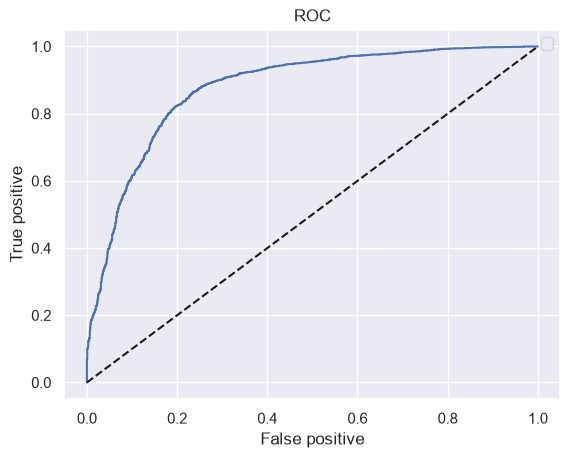

In [65]:
plt.plot(fpr, tpr)
plt.plot(fpr,fpr, linestyle = '--', color = 'k')
plt.xlabel('False positive')
plt.ylabel('True positive')
plt.legend()
plt.title('ROC')

In [66]:
auroc = roc_auc_score(y_test_pred_proba['y_test'], y_test_pred_proba['y_pred_proba'])
auroc

0.877732063337998

### Gini & KS

In [67]:
y_test_pred_proba

,y_test,y_pred_proba,y_pred
14447,1,0.9287,1
24610,1,0.9356,1
11096,1,0.9918,1
10424,0,0.3819,0
12628,1,0.6470,1
...,...,...,...
32245,1,0.9705,1
13814,1,0.9792,1
30630,0,0.2941,0
2862,1,0.9825,1


In [68]:
y_test_pred_proba = y_test_pred_proba.sort_values(by='y_pred_proba')

In [69]:
y_test_pred_proba = y_test_pred_proba.reset_index(drop=False)

In [70]:
y_test_pred_proba

,index,y_test,y_pred_proba,y_pred
0,5908,0,0.0053,0
1,12169,0,0.0120,0
2,23186,0,0.0123,0
3,3639,0,0.0132,0
4,17495,0,0.0139,0
...,...,...,...,...
6510,26982,1,0.9985,1
6511,13728,1,0.9985,1
6512,31481,1,0.9987,1
6513,9704,1,0.9988,1


In [71]:
y_test_pred_proba['Cumulative n_borrowers'] = y_test_pred_proba.index + 1
y_test_pred_proba['Cumulative n_good'] = y_test_pred_proba['y_test'].cumsum()
y_test_pred_proba['Cumulative n_bad'] = y_test_pred_proba['Cumulative n_borrowers'] - y_test_pred_proba['y_test'].cumsum()                                     


In [72]:
y_test_pred_proba['Cumulative pct_borrowers'] = y_test_pred_proba['Cumulative n_borrowers'] / y_test_pred_proba.shape[0]
y_test_pred_proba['Cumulative pct_good'] = y_test_pred_proba['Cumulative n_good'] / y_test_pred_proba['y_test'].sum()
y_test_pred_proba['Cumulative pct_bad'] = y_test_pred_proba['Cumulative n_bad'] / (y_test_pred_proba.shape[0] - y_test_pred_proba['y_test'].sum())

Text(0.5, 1.0, 'Gini')

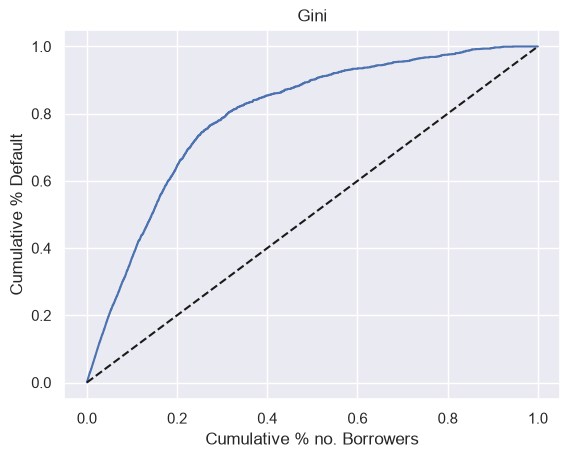

In [73]:
plt.plot(y_test_pred_proba['Cumulative pct_borrowers'], y_test_pred_proba['Cumulative pct_bad'])
plt.plot(y_test_pred_proba['Cumulative pct_borrowers'], y_test_pred_proba['Cumulative pct_borrowers'],
        linestyle = '--', color = 'k')
plt.xlabel('Cumulative % no. Borrowers')
plt.ylabel('Cumulative % Default')
plt.title('Gini')

In [74]:
Gini = auroc * 2 - 1
Gini

0.755464126675996

C:\Users\admin\AppData\Local\Temp\ipykernel_15888\474408212.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Kolgomorov-Smirnov')

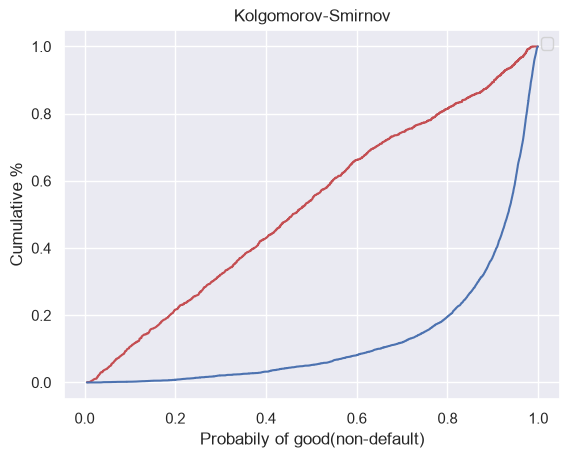

In [75]:
# KS

plt.plot(y_test_pred_proba['y_pred_proba'], y_test_pred_proba['Cumulative pct_bad'], color = 'r')
plt.plot(y_test_pred_proba['y_pred_proba'], y_test_pred_proba['Cumulative pct_good'], color = 'b')
plt.xlabel('Probabily of good(non-default)')
plt.ylabel('Cumulative %')
plt.legend()
plt.title('Kolgomorov-Smirnov')

In [76]:
KS = max(y_test_pred_proba['Cumulative pct_bad'] - y_test_pred_proba['Cumulative pct_good'])

In [77]:
KS

0.6287253898238604

### Scorecard

In [78]:
pd.options.display.max_columns = None

In [79]:
summary_table

,Feature name,Coefs,p-value
0,Intercept,-2.8980,0.0000
1,person_home_ownership:MORTGAGE,0.8197,0.0000
2,person_home_ownership:OWN,2.4778,0.0000
3,loan_intent:EDUCATION,0.8598,0.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121
5,loan_intent:MEDICAL,0.1903,0.0015
6,loan_intent:PERSONAL,0.6338,0.0000
7,loan_intent:VENTURE,1.0737,0.0000
8,loan_grade:A,3.3535,0.0000
9,loan_grade:B,3.3474,0.0000


In [80]:
ref_categories

['person_home_ownership:RENT_OTHER',
 'loan_intent:DEBTCONSOLIDATION',
 'loan_grade:G',
 'person_emp_length:<1',
 'loan_int_rate:<9.45',
 'cb_person_cred_hist_length:<=3',
 'person_income:<25000',
 'loan_percent_income:<0.07']

In [81]:
df_ref_categories = pd.DataFrame(ref_categories, columns=[summary_table.columns[0]])

In [82]:
df_ref_categories['Coefs'] = 0
df_ref_categories['p-value'] = np.nan

In [83]:
df_ref_categories

,Feature name,Coefs,p-value
0,person_home_ownership:RENT_OTHER,0,NaN
1,loan_intent:DEBTCONSOLIDATION,0,NaN
2,loan_grade:G,0,NaN
3,person_emp_length:<1,0,NaN
4,loan_int_rate:<9.45,0,NaN
5,cb_person_cred_hist_length:<=3,0,NaN
6,person_income:<25000,0,NaN
7,loan_percent_income:<0.07,0,NaN


In [84]:
score_card = pd.concat([summary_table, df_ref_categories], axis=0)
score_card = score_card.reset_index(drop=True)

In [85]:
score_card

,Feature name,Coefs,p-value
0,Intercept,-2.8980,0.0000
1,person_home_ownership:MORTGAGE,0.8197,0.0000
2,person_home_ownership:OWN,2.4778,0.0000
3,loan_intent:EDUCATION,0.8598,0.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121
5,loan_intent:MEDICAL,0.1903,0.0015
6,loan_intent:PERSONAL,0.6338,0.0000
7,loan_intent:VENTURE,1.0737,0.0000
8,loan_grade:A,3.3535,0.0000
9,loan_grade:B,3.3474,0.0000


In [86]:
score_card.rename(columns={'Feature name':'Categories'}, inplace=True)

In [87]:
score_card['Feature'] = score_card['Categories'].str.split(':').str[0]

In [88]:
score_card

,Categories,Coefs,p-value,Feature
0,Intercept,-2.8980,0.0000,Intercept
1,person_home_ownership:MORTGAGE,0.8197,0.0000,person_home_ownership
2,person_home_ownership:OWN,2.4778,0.0000,person_home_ownership
3,loan_intent:EDUCATION,0.8598,0.0000,loan_intent
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121,loan_intent
5,loan_intent:MEDICAL,0.1903,0.0015,loan_intent
6,loan_intent:PERSONAL,0.6338,0.0000,loan_intent
7,loan_intent:VENTURE,1.0737,0.0000,loan_intent
8,loan_grade:A,3.3535,0.0000,loan_grade
9,loan_grade:B,3.3474,0.0000,loan_grade


### Calculate Credit Score

In [89]:
min_CIC = 150
max_CIC = 750
CIC_range = max_CIC - min_CIC

In [90]:
score_card.groupby('Feature')['Coefs'].min()

Feature
Intercept                    -2.8980
cb_person_cred_hist_length    0.0000
loan_grade                    0.0000
loan_int_rate                -0.4252
loan_intent                  -0.0462
loan_percent_income          -2.0441
person_emp_length             0.0000
person_home_ownership         0.0000
person_income                 0.0000
Name: Coefs, dtype: float64

In [91]:
min_sum_coefs = score_card.groupby('Feature')['Coefs'].min().sum()
min_sum_coefs

np.float64(-5.413552011881988)

In [92]:
max_sum_coefs = score_card.groupby('Feature')['Coefs'].max().sum()
max_sum_coefs

np.float64(6.6771468888361)

In [93]:
score_card['Score'] = score_card['Coefs'] * ((max_CIC - min_CIC)/(max_sum_coefs - min_sum_coefs)) 

In [94]:
score_card.loc[0, 'Score'] = (score_card['Coefs'][0] - min_sum_coefs) / (max_sum_coefs - min_sum_coefs) * CIC_range + min_CIC

In [95]:
score_card['Score_edit'] = score_card['Score'].round()
score_card

,Categories,Coefs,p-value,Feature,Score,Score_edit
0,Intercept,-2.8980,0.0000,Intercept,274.8328,275.0000
1,person_home_ownership:MORTGAGE,0.8197,0.0000,person_home_ownership,40.6779,41.0000
2,person_home_ownership:OWN,2.4778,0.0000,person_home_ownership,122.9598,123.0000
3,loan_intent:EDUCATION,0.8598,0.0000,loan_intent,42.6688,43.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121,loan_intent,-2.2932,-2.0000
5,loan_intent:MEDICAL,0.1903,0.0015,loan_intent,9.4443,9.0000
6,loan_intent:PERSONAL,0.6338,0.0000,loan_intent,31.4503,31.0000
7,loan_intent:VENTURE,1.0737,0.0000,loan_intent,53.2809,53.0000
8,loan_grade:A,3.3535,0.0000,loan_grade,166.4165,166.0000
9,loan_grade:B,3.3474,0.0000,loan_grade,166.1143,166.0000


In [96]:
min_CIC_scorecard = score_card.groupby('Feature')['Score_edit'].min().sum()
max_CIC_scorecard = score_card.groupby('Feature')['Score_edit'].max().sum()
print(f'min: {min_CIC_scorecard},       max: {max_CIC_scorecard} ')

min: 151.0,       max: 750.0 


In [97]:
# Adjust min

score_card['Diff'] = score_card['Score_edit'] - score_card['Score']
score_card

,Categories,Coefs,p-value,Feature,Score,Score_edit,Diff
0,Intercept,-2.8980,0.0000,Intercept,274.8328,275.0000,0.1672
1,person_home_ownership:MORTGAGE,0.8197,0.0000,person_home_ownership,40.6779,41.0000,0.3221
2,person_home_ownership:OWN,2.4778,0.0000,person_home_ownership,122.9598,123.0000,0.0402
3,loan_intent:EDUCATION,0.8598,0.0000,loan_intent,42.6688,43.0000,0.3312
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121,loan_intent,-2.2932,-2.0000,0.2932
5,loan_intent:MEDICAL,0.1903,0.0015,loan_intent,9.4443,9.0000,-0.4443
6,loan_intent:PERSONAL,0.6338,0.0000,loan_intent,31.4503,31.0000,-0.4503
7,loan_intent:VENTURE,1.0737,0.0000,loan_intent,53.2809,53.0000,-0.2809
8,loan_grade:A,3.3535,0.0000,loan_grade,166.4165,166.0000,-0.4165
9,loan_grade:B,3.3474,0.0000,loan_grade,166.1143,166.0000,-0.1143


In [98]:
score_card['Score_final'] = score_card['Score_edit']

In [99]:
score_card.loc[score_card['Feature'] == 'loan_percent_income', ['Score','Diff','Score_final']]

,Score,Diff,Score_final
33,-7.1338,0.1338,-7.0000
34,2.7967,0.2033,3.0000
35,-9.0651,0.0651,-9.0000
36,-101.4377,0.4377,-101.0000
44,0.0000,0.0000,0.0000


In [100]:
score_card

,Categories,Coefs,p-value,Feature,Score,Score_edit,Diff,Score_final
0,Intercept,-2.8980,0.0000,Intercept,274.8328,275.0000,0.1672,275.0000
1,person_home_ownership:MORTGAGE,0.8197,0.0000,person_home_ownership,40.6779,41.0000,0.3221,41.0000
2,person_home_ownership:OWN,2.4778,0.0000,person_home_ownership,122.9598,123.0000,0.0402,123.0000
3,loan_intent:EDUCATION,0.8598,0.0000,loan_intent,42.6688,43.0000,0.3312,43.0000
4,loan_intent:HOMEIMPROVEMENT,-0.0462,0.5121,loan_intent,-2.2932,-2.0000,0.2932,-2.0000
5,loan_intent:MEDICAL,0.1903,0.0015,loan_intent,9.4443,9.0000,-0.4443,9.0000
6,loan_intent:PERSONAL,0.6338,0.0000,loan_intent,31.4503,31.0000,-0.4503,31.0000
7,loan_intent:VENTURE,1.0737,0.0000,loan_intent,53.2809,53.0000,-0.2809,53.0000
8,loan_grade:A,3.3535,0.0000,loan_grade,166.4165,166.0000,-0.4165,166.0000
9,loan_grade:B,3.3474,0.0000,loan_grade,166.1143,166.0000,-0.1143,166.0000


In [101]:
score_card.groupby('Feature')['Score_final'].min()

Feature
Intercept                     275.0000
cb_person_cred_hist_length      0.0000
loan_grade                      0.0000
loan_int_rate                 -21.0000
loan_intent                    -2.0000
loan_percent_income          -101.0000
person_emp_length               0.0000
person_home_ownership           0.0000
person_income                   0.0000
Name: Score_final, dtype: float64

In [102]:
#reround 
score_card.loc[36, 'Score_final'] = -102

In [103]:
min_CIC_scorecard = score_card.groupby('Feature')['Score_final'].min().sum()
max_CIC_scorecard = score_card.groupby('Feature')['Score_final'].max().sum()
print(f'min: {min_CIC_scorecard},       max: {max_CIC_scorecard} ')

min: 150.0,       max: 750.0 


In [104]:
#Cut-offs

df_cutoffs = pd.concat([pd.DataFrame(thresh), pd.DataFrame(fpr), pd.DataFrame(tpr)], axis=1) 

In [105]:
df_cutoffs.columns = ['threshold', 'fpr', 'tpr']
df_cutoffs.head()

,threshold,fpr,tpr
0,inf,0.0000,0.0000
1,0.9992,0.0000,0.0002
2,0.9969,0.0000,0.0071
3,0.9968,0.0000,0.0075
4,0.9965,0.0000,0.0100


In [106]:
thresh

array([       inf, 0.99916341, 0.99685563, ..., 0.02674266, 0.02629494,
       0.00530466], shape=(1964,))

In [107]:
df_cutoffs.iloc[0,0] = 1 - 1/np.power(10,20)

In [108]:
df_cutoffs['Score'] = ((np.log(df_cutoffs['threshold']/(1-df_cutoffs['threshold'])) - min_sum_coefs) * (max_CIC - min_CIC)/(max_sum_coefs - min_sum_coefs) + min_CIC).round()

In [109]:
df_cutoffs.iloc[0,-1] = max_CIC
df_cutoffs

,threshold,fpr,tpr,Score
0,1.0000,0.0000,0.0000,750.0000
1,0.9992,0.0000,0.0002,770.0000
2,0.9969,0.0000,0.0071,704.0000
3,0.9968,0.0000,0.0075,704.0000
4,0.9965,0.0000,0.0100,699.0000
...,...,...,...,...
1959,0.0302,0.9809,0.9998,247.0000
1960,0.0291,0.9838,0.9998,245.0000
1961,0.0267,0.9887,0.9998,240.0000
1962,0.0263,0.9887,1.0000,239.0000


In [110]:
df_cutoffs.drop(index=1, inplace=True) #drop outlier threshold
df_cutoffs.reset_index(drop=True, inplace= True)

In [111]:
df_cutoffs

,threshold,fpr,tpr,Score
0,1.0000,0.0000,0.0000,750.0000
1,0.9969,0.0000,0.0071,704.0000
2,0.9968,0.0000,0.0075,704.0000
3,0.9965,0.0000,0.0100,699.0000
4,0.9965,0.0000,0.0104,699.0000
...,...,...,...,...
1958,0.0302,0.9809,0.9998,247.0000
1959,0.0291,0.9838,0.9998,245.0000
1960,0.0267,0.9887,0.9998,240.0000
1961,0.0263,0.9887,1.0000,239.0000


In [112]:
# Calculate number of approvals
def n_approvals(threshold):
    return np.where(y_test_pred_proba['y_pred_proba'] >= threshold, 1, 0).sum()

In [113]:
df_cutoffs['No. Approvals'] = df_cutoffs['threshold'].apply(n_approvals)
df_cutoffs['No. Rejected'] = y_test_pred_proba['y_pred_proba'].shape[0] - df_cutoffs['No. Approvals']
df_cutoffs['Approval Rate'] = df_cutoffs['No. Approvals'] / y_test_pred_proba['y_pred_proba'].shape[0] 
df_cutoffs['Rejection Rate'] = 1 - df_cutoffs['Approval Rate'] 

In [114]:
df_cutoffs.head()

,threshold,fpr,tpr,Score,No. Approvals,No. Rejected,Approval Rate,Rejection Rate
0,1.0000,0.0000,0.0000,750.0000,0,6515,0.0000,1.0000
1,0.9969,0.0000,0.0071,704.0000,36,6479,0.0055,0.9945
2,0.9968,0.0000,0.0075,704.0000,38,6477,0.0058,0.9942
3,0.9965,0.0000,0.0100,699.0000,51,6464,0.0078,0.9922
4,0.9965,0.0000,0.0104,699.0000,53,6462,0.0081,0.9919


In [115]:
def filter_by_threshold(threshold):
    return df_cutoffs.loc[df_cutoffs['threshold'] > threshold, :]

In [116]:
filter_by_threshold(0.5)

,threshold,fpr,tpr,Score,No. Approvals,No. Rejected,Approval Rate,Rejection Rate
0,1.0000,0.0000,0.0000,750.0000,0,6515,0.0000,1.0000
1,0.9969,0.0000,0.0071,704.0000,36,6479,0.0055,0.9945
2,0.9968,0.0000,0.0075,704.0000,38,6477,0.0058,0.9942
3,0.9965,0.0000,0.0100,699.0000,51,6464,0.0078,0.9922
4,0.9965,0.0000,0.0104,699.0000,53,6462,0.0081,0.9919
...,...,...,...,...,...,...,...,...
1559,0.5047,0.4470,0.9474,420.0000,5464,1051,0.8387,0.1613
1560,0.5030,0.4527,0.9474,419.0000,5472,1043,0.8399,0.1601
1561,0.5024,0.4541,0.9476,419.0000,5475,1040,0.8404,0.1596
1562,0.5013,0.4555,0.9476,419.0000,5477,1038,0.8407,0.1593
